1. Nodes - Phython function
2. Edges - Connect the nodes - Conditional Edges
3. State - State Schema Serves as the input for all Nodes and Edges
4. StateGraph - Structure of Entire Graph

In [8]:
from typing_extensions import TypedDict
class state(TypedDict):
    graph_info : str

In [7]:
import truststore   
truststore.inject_into_ssl()

ModuleNotFoundError: No module named 'truststore'

### Nodes - Nodes are just phython function.

In [9]:
def start_play(state : state) :
    print("Start_Play Node has been called")
    return {"graph_info": state["graph_info"] + " I am planning to play"}

def cricket(state : state) :
    print("Cricket Node has been called")
    return {"graph_info": state["graph_info"] + " cricket"}

def badminton(state : state) :
    print("Badminton Node has been called")
    return {"graph_info": state["graph_info"] + " Badminton"}

In [12]:
import random
from typing import Literal

def random_play(state : state) -> Literal["cricket", "badminton"]:
    graph_info = state["graph_info"]
    choice = random.choice(["cricket", "badminton"])
    return choice

### Graph Construction
StateGraph Class we can use
Visualize the graph as Mermaid diagram

Note: you may need to restart the kernel to use updated packages.


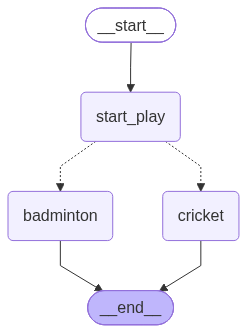

In [13]:
%pip install langgraph

from IPython.display import display
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

graph = StateGraph(state)

graph.add_node("start_play", start_play)
graph.add_node("cricket", cricket)
graph.add_node("badminton", badminton)

graph.add_edge(START, "start_play")
graph.add_conditional_edges("start_play", random_play)
graph.add_edge("cricket", END)
graph.add_edge("badminton", END)

graph_builder = graph.compile()

display(Image(graph_builder.get_graph().draw_mermaid_png()))




### Graph Invocation

In [14]:
graph_builder.invoke({"graph_info": "My name is Navdeep."})

Start_Play Node has been called
Cricket Node has been called


{'graph_info': 'My name is Navdeep. I am planning to play cricket'}